# Student Marks Prediction using Machine Learning

## Objective
Predict a student's exam marks based on study hours and attendance.

## Problem Type
Supervised Learning - Regression

## Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn


In [ ]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Jupyter is working!")

Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
Jupyter is working!


In [ ]:
data = {
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "attendance": [50, 55, 60, 65, 70, 75, 85, 90],
    "marks": [20, 25, 40, 45, 60, 65, 80, 90]
}

df = pd.DataFrame(data)

display(df)

,study_hours,attendance,marks
0,1,50,20
1,2,55,25
2,3,60,40
3,4,65,45
4,5,70,60
5,6,75,65
6,7,85,80
7,8,90,90


In [ ]:
# 1. Check number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types and missing values
print("\nDataset information:")
df.info()

# 4. Get statistical information
print("\nStatistical summary:")
display(df.describe())

Dataset shape: (8, 3)

Column names:
['study_hours', 'attendance', 'marks']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   study_hours  8 non-null      int64
 1   attendance   8 non-null      int64
 2   marks        8 non-null      int64
dtypes: int64(3)
memory usage: 324.0 bytes

Statistical summary:


,study_hours,attendance,marks
count,8.00000,8.00000,8.000000
mean,4.50000,68.75000,53.125000
std,2.44949,14.07886,25.062422
min,1.00000,50.00000,20.000000
25%,2.75000,58.75000,36.250000
50%,4.50000,67.50000,52.500000
75%,6.25000,77.50000,68.750000
max,8.00000,90.00000,90.000000


In [ ]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Check the cleaned dataset
print("\nDataset after cleaning:")
display(df)

Missing values:
study_hours    0
attendance     0
marks          0
dtype: int64

Duplicate rows: 0

Dataset after cleaning:


,study_hours,attendance,marks
0,1,50,20
1,2,55,25
2,3,60,40
3,4,65,45
4,5,70,60
5,6,75,65
6,7,85,80
7,8,90,90


In [ ]:
import matplotlib.pyplot as plt

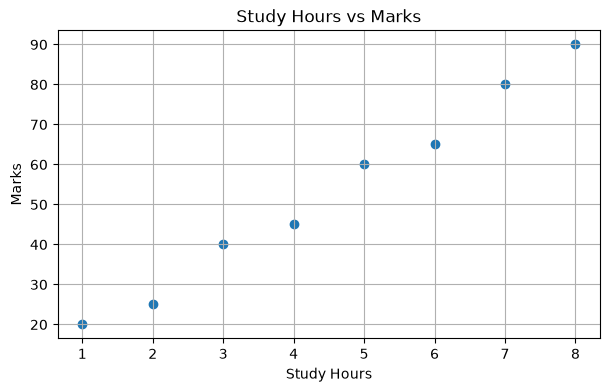

In [ ]:
plt.figure(figsize=(7, 4))

plt.scatter(df["study_hours"], df["marks"])

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")

plt.grid(True)
plt.show()

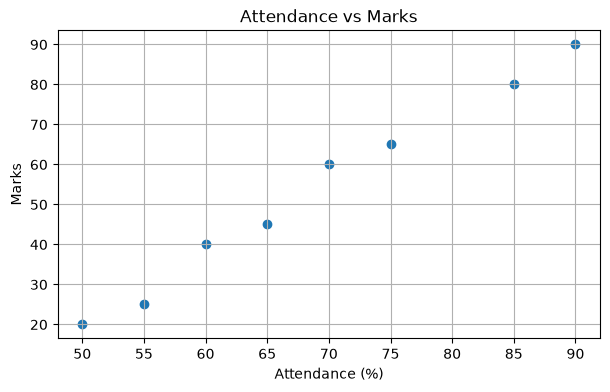

In [ ]:
plt.figure(figsize=(7, 4))

plt.scatter(df["attendance"], df["marks"])

plt.xlabel("Attendance (%)")
plt.ylabel("Marks")
plt.title("Attendance vs Marks")

plt.grid(True)
plt.show()

In [ ]:
# Features: inputs given to the model
X = df[["study_hours", "attendance"]]

# Target: value the model learns to predict
y = df["marks"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (8, 2)
Target shape: (8,)


,study_hours,attendance
0,1,50
1,2,55
2,3,60
3,4,65
4,5,70


0    20
1    25
2    40
3    45
4    60
Name: marks, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nTraining data:")
display(X_train)

print("\nTesting data:")
display(X_test)

Training features: (6, 2)
Testing features: (2, 2)

Training targets: (6,)
Testing targets: (2,)

Training data:


,study_hours,attendance
0,1,50
7,8,90
2,3,60
4,5,70
3,4,65
6,7,85



Testing data:


,study_hours,attendance
1,2,55
5,6,75


In [ ]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Model training completed!
Intercept: -16.689189189189257
Coefficients: [6.62162162 0.59459459]


In [ ]:
# Predict marks for test records
y_pred = model.predict(X_test)

print("Actual marks:")
print(y_test.to_list())

print("\nPredicted marks:")
print(y_pred)

Actual marks:
[25, 65]

Predicted marks:
[29.25675676 67.63513514]


In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R² Score:", r2)

MAE: 3.4459459459459545
MSE: 12.531957633309066
R² Score: 0.9686701059167273


In [ ]:
results = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred
})

results["Absolute Error"] = abs(
    results["Actual Marks"] - results["Predicted Marks"]
)

display(results.round(2))

,Actual Marks,Predicted Marks,Absolute Error
0,25,29.26,4.26
1,65,67.64,2.64


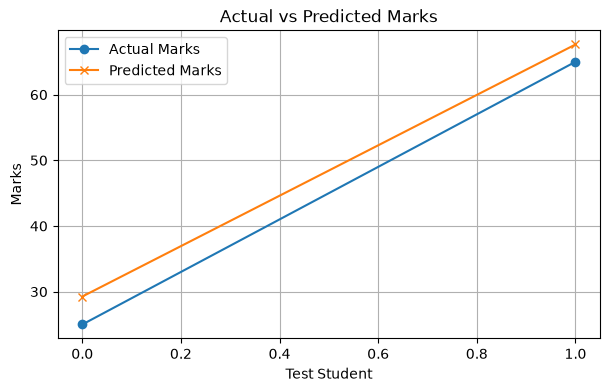

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker="o",
    label="Actual Marks"
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker="x",
    label="Predicted Marks"
)

plt.xlabel("Test Student")
plt.ylabel("Marks")
plt.title("Actual vs Predicted Marks")
plt.legend()
plt.grid(True)
    
plt.show()

In [ ]:
new_student = pd.DataFrame({
    "study_hours": [5],
    "attendance": [70]
})

predicted_marks = model.predict(new_student)

print("Predicted marks:", round(predicted_marks[0], 2))

Predicted marks: 58.04
